**NBA Elo EDA · Part 1 of 4.** Data quality and first look.

**Dataset:** NBA All Elo (NBA & ABA game results with Elo ratings), [FiveThirtyEight](https://github.com/fivethirtyeight/data/tree/master/nba-elo), CC BY 4.0. Parts: [1](01_data_quality.ipynb) · [2](02_distributions_outliers.ipynb) · [3](03_bivariate.ipynb) · [4](04_groups_multivariate.ipynb)

# Part 1 — NBA All Elo Dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
%matplotlib inline

In [2]:
# Load the dataset (uses a local cache after the first run, otherwise
# downloads it from the original public source below)
DATA_URL = "https://raw.githubusercontent.com/fivethirtyeight/data/master/nba-elo/nbaallelo.csv"
CACHE_PATH = "data/nbaallelo.csv"

if os.path.exists(CACHE_PATH):
    df = pd.read_csv(CACHE_PATH)
else:
    df = pd.read_csv(DATA_URL)
    os.makedirs("data", exist_ok=True)
    df.to_csv(CACHE_PATH, index=False)

df.shape

(110902, 23)

## Section 1: Dataset Introduction

**Dataset name:** NBA All Elo
**Source:** FiveThirtyEight's public data repository on GitHub (`fivethirtyeight/data`, folder `nba-elo`), originally built for their article on how FiveThirtyEight calculates historical Elo ratings for NBA and ABA teams.

**Size:** 110,902 observations and 23 variables.

**What one observation represents:** each row is **one team's participation in one professional basketball game** (NBA or ABA), covering the 1946–47 season through the 2009 season. Because every game involves two teams, each real game appears **twice** in the table — once from each team's perspective (`_iscopy` marks the mirrored row). There are 55,451 unique games in total.

**Most important variables:**
- `year_id`, `date_game`, `seasongame` — when the game was played, and which game of the season it was for that team.
- `lg_id` — league: `NBA` or `ABA` (the ABA merged into the NBA after the 1976 season).
- `team_id` / `fran_id`, `opp_id` / `opp_fran` — the team and its opponent. `team_id` reflects the exact franchise code used that season (101 distinct codes, since teams relocated/renamed over time), while `fran_id` groups those into 53 stable franchise identities.
- `pts` / `opp_pts` — points scored by the team and by its opponent in that game.
- `elo_i` / `elo_n` — the team's Elo rating going into the game and coming out of it.
- `forecast` — the pre-game, Elo-based probability that this team would win.
- `game_location` — `H` (home), `A` (away), or `N` (neutral site).
- `game_result` — `W` or `L`.
- `is_playoffs` — 0 for regular season, 1 for playoffs.

In my own words: this is a game-by-game box-score-style log of essentially the entire history of major U.S. professional basketball through 2009, enriched with a running Elo skill rating for every team. It lets us study things a plain win/loss record can't — like how "surprising" a result was (via `forecast`), not just who won.

In [3]:
df.head()

,gameorder,game_id,lg_id,_iscopy,year_id,date_game,seasongame,is_playoffs,team_id,fran_id,pts,elo_i,elo_n,win_equiv,opp_id,opp_fran,opp_pts,opp_elo_i,opp_elo_n,game_location,game_result,forecast,notes
0,1,194611010TRH,NBA,0,1947,11/1/1946,1,0,TRH,Huskies,66,1300.0000,1293.2767,40.294830,NYK,Knicks,68,1300.0000,1306.7233,H,L,0.640065,NaN
1,1,194611010TRH,NBA,1,1947,11/1/1946,1,0,NYK,Knicks,68,1300.0000,1306.7233,41.705170,TRH,Huskies,66,1300.0000,1293.2767,A,W,0.359935,NaN
2,2,194611020CHS,NBA,0,1947,11/2/1946,1,0,CHS,Stags,63,1300.0000,1309.6521,42.012257,NYK,Knicks,47,1306.7233,1297.0712,H,W,0.631101,NaN
3,2,194611020CHS,NBA,1,1947,11/2/1946,2,0,NYK,Knicks,47,1306.7233,1297.0712,40.692783,CHS,Stags,63,1300.0000,1309.6521,A,L,0.368899,NaN
4,3,194611020DTF,NBA,0,1947,11/2/1946,1,0,DTF,Falcons,33,1300.0000,1279.6189,38.864048,WSC,Capitols,50,1300.0000,1320.3811,H,L,0.640065,NaN


## Section 2: Exploratory Questions

1. Has average scoring (points per game) changed over the decades, or has it stayed roughly constant?
2. Do home teams have an advantage over away teams, in both win rate and points scored?
3. Do playoff games differ from regular-season games in how many points are scored?
4. Is the pre-game Elo-based win forecast actually a good predictor of who wins?
5. Are there unusual or extreme scoring values in the data (blowouts, oddly low scores, or data-quality artifacts)?

## Section 3: Expectations

| Question | Expectation |
|---|---|
| 1. Has scoring changed over the decades? | I expect a fairly steady **increase** over time, since the modern game is usually described as faster-paced with more three-point shooting. |
| 2. Do home teams have an advantage? | I expect a **moderate home advantage**, maybe around a 55–58% home win rate, due to crowd support and no travel fatigue. |
| 3. Do playoff games score differently? | I expect **lower scoring in the playoffs**, because defensive intensity and preparation increase when teams face the same opponent repeatedly in a series. |
| 4. Is the Elo forecast a good predictor? | I expect forecast probability to be **reasonably well calibrated** — teams given a higher win probability should win more often — since Elo is specifically designed for this purpose. |
| 5. Are there unusual/extreme values? | I expect a few **high-scoring outliers** from overtime games, and possibly some **data-entry artifacts** (e.g. forfeits or suspended games) rather than genuine 0-point performances. |

## Section 4: Initial Data Exploration

In [4]:
df.shape

(110902, 23)

110,902 rows and 23 columns, as noted in Section 1.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110902 entries, 0 to 110901
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   gameorder      110902 non-null  int64  
 1   game_id        110902 non-null  str    
 2   lg_id          110902 non-null  str    
 3   _iscopy        110902 non-null  int64  
 4   year_id        110902 non-null  int64  
 5   date_game      110902 non-null  str    
 6   seasongame     110902 non-null  int64  
 7   is_playoffs    110902 non-null  int64  
 8   team_id        110902 non-null  str    
 9   fran_id        110902 non-null  str    
 10  pts            110902 non-null  int64  
 11  elo_i          110902 non-null  float64
 12  elo_n          110902 non-null  float64
 13  win_equiv      110902 non-null  float64
 14  opp_id         110902 non-null  str    
 15  opp_fran       110902 non-null  str    
 16  opp_pts        110902 non-null  int64  
 17  opp_elo_i      110902 non-null  float64


`df.info()` shows that most columns are stored as `int64` or `float64`, and the identifier/category-like columns (`game_id`, `lg_id`, `team_id`, `fran_id`, `opp_id`, `opp_fran`, `date_game`, `game_location`, `game_result`, `notes`) are stored as generic string objects. `date_game` is a date but is not yet parsed as a datetime — this is a data-type issue I address in Section 5.

In [6]:
df.dtypes

gameorder          int64
game_id              str
lg_id                str
_iscopy            int64
year_id            int64
date_game            str
seasongame         int64
is_playoffs        int64
team_id              str
fran_id              str
pts                int64
elo_i            float64
elo_n            float64
win_equiv        float64
opp_id               str
opp_fran             str
opp_pts            int64
opp_elo_i        float64
opp_elo_n        float64
game_location        str
game_result          str
forecast         float64
notes                str
dtype: object

In [7]:
df.describe()

,gameorder,_iscopy,year_id,seasongame,is_playoffs,pts,elo_i,elo_n,win_equiv,opp_pts,opp_elo_i,opp_elo_n,forecast
count,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000,110902.000000
mean,27726.000000,0.500000,1984.825233,43.492516,0.062506,103.229049,1492.730380,1492.730380,41.674053,103.229049,1492.730380,1492.730380,0.499994
std,16007.397055,0.500002,16.071935,25.345516,0.242073,15.104216,111.434163,111.747258,10.512602,15.104216,111.434163,111.747258,0.214333
min,1.000000,0.000000,1947.000000,1.000000,0.000000,0.000000,1091.644500,1085.774400,10.152501,0.000000,1091.644500,1085.774400,0.000000
25%,13863.250000,0.000000,1973.000000,22.000000,0.000000,93.000000,1415.690900,1415.504150,34.217916,93.000000,1415.690900,1415.504150,0.329004
50%,27726.000000,0.500000,1986.000000,43.000000,0.000000,103.000000,1498.820500,1498.841650,42.052820,103.000000,1498.820500,1498.841650,0.499984
75%,41588.750000,1.000000,1998.000000,65.000000,0.000000,113.000000,1572.473575,1572.701675,49.448690,113.000000,1572.473575,1572.701675,0.670987
max,55451.000000,1.000000,2009.000000,108.000000,1.000000,186.000000,1853.104500,1853.104500,71.112038,186.000000,1853.104500,1853.104500,0.979553


Some things stand out in `df.describe()`:
- `pts` and `opp_pts` have **identical** summary statistics (mean ≈ 103.2, std ≈ 15.1, min 0, max 186). That makes sense given the row structure: every game contributes one row where a given score is `pts` and another row (the mirrored one) where the *same* score is `opp_pts`.
- `elo_i` and `elo_n` (Elo rating before/after the game) range from about 1092 to 1853, centered close to the starting value of 1500, which matches how Elo systems are designed to behave.
- `forecast` (pre-game win probability) ranges from 0 to about 0.98 with a mean very close to 0.50 — expected, since forecasts for two opposing teams in the same game must sum to (approximately) 1.

In [8]:
df.nunique()

gameorder         55451
game_id           55451
lg_id                 2
_iscopy               2
year_id              63
date_game         11187
seasongame          108
is_playoffs           2
team_id             101
fran_id              53
pts                 139
elo_i            109038
elo_n            109075
win_equiv        108964
opp_id              101
opp_fran             53
opp_pts             139
opp_elo_i        109038
opp_elo_n        109075
game_location         3
game_result           2
forecast         109928
notes               228
dtype: int64

`nunique()` confirms the row structure described in Section 1: there are 55,451 unique `game_id` values but 110,902 rows, i.e. each game is stored twice. It also shows **101** distinct `team_id` codes but only **53** distinct `fran_id` values — a sign that many franchises changed city or name over the years and were assigned a new `team_id`, while `fran_id` keeps them linked to one continuous franchise history.

In [9]:
df["lg_id"].value_counts()

lg_id
NBA    102604
ABA      8298
Name: count, dtype: int64

In [10]:
df["game_location"].value_counts()

game_location
H    55438
A    55438
N       26
Name: count, dtype: int64

In [11]:
df["game_result"].value_counts()

game_result
L    55451
W    55451
Name: count, dtype: int64

In [12]:
df["is_playoffs"].value_counts()

is_playoffs
0    103970
1      6932
Name: count, dtype: int64

From the categorical summaries: the dataset is dominated by the **NBA** (102,604 rows) with a much smaller **ABA** slice (8,298 rows, 1968–1976, before the ABA–NBA merger). Most games are **regular season** (103,970 rows) rather than **playoffs** (6,932 rows). `game_result` is exactly balanced between `W` and `L`, which must be true by construction since every game has one winner and one loser. `game_location` is almost exactly balanced between `H` and `A` (55,438 each), with only 26 games played at a **neutral** site.

## Section 5: Basic Data Quality Check

In [13]:
df.isna().sum()

gameorder             0
game_id               0
lg_id                 0
_iscopy               0
year_id               0
date_game             0
seasongame            0
is_playoffs           0
team_id               0
fran_id               0
pts                   0
elo_i                 0
elo_n                 0
win_equiv             0
opp_id                0
opp_fran              0
opp_pts               0
opp_elo_i             0
opp_elo_n             0
game_location         0
game_result           0
forecast              0
notes            105490
dtype: int64

Only one column has missing values: `notes`, which is empty for 105,490 of 110,902 rows (about 95%). This is expected rather than a problem — `notes` is a free-text field only filled in for unusual games (forfeits, neutral-site details, etc.), so most games simply have nothing to note.

In [14]:
df.duplicated().sum()

np.int64(0)

There are **0 exactly duplicated rows**. However, as discussed in Section 4, each real-world game legitimately appears as **two** rows (one per team) — this is a designed feature of the dataset, not a duplication error, so it should not be removed.

In [15]:
# Data type check: date_game is stored as text, not as a real date
df["date_game"].head(3)

0    11/1/1946
1    11/1/1946
2    11/2/1946
Name: date_game, dtype: str

**Inappropriate data type:** `date_game` is stored as a plain string (e.g. `"11/1/1946"`) rather than a proper datetime. This matters because it prevents direct date arithmetic or correct chronological sorting/plotting without first converting it. I use `year_id` for time-based analysis below, since it is already numeric, but a full analysis would convert `date_game` with `pd.to_datetime`.

In [16]:
# Suspicious value check: is a 0-point game real, or a data artifact?
df[df["pts"] == 0][["date_game", "team_id", "pts", "opp_id", "opp_pts", "notes"]]

,date_game,team_id,pts,opp_id,opp_pts,notes
26684,10/26/1972,DNR,0,VIR,2,at Richmond VA; forfeit to VIR


**Suspicious value:** there is exactly one game where a team scored **0 points** — the `notes` field explains that this was a **forfeit** (Denver Rockets forfeited to the Virginia Squires in 1972), not a genuinely played 0-point game. This is important: if this row were included in scoring analysis without checking `notes`, it would incorrectly drag down summary statistics and could be mistaken for a data-entry error rather than what it actually is (a game that was not really played to completion).

**Inconsistent categories:** as noted above, `team_id` has 101 distinct codes for only 53 real franchises (`fran_id`), because relocated/renamed teams (e.g. franchises that moved cities) received new codes. Any analysis that groups by `team_id` alone would incorrectly split a single franchise's history into multiple entities — `fran_id` should be used instead when franchise-level continuity matters. I do not perform further cleaning here, as instructed, but keep this in mind when interpreting groupings below.

## Section 6: First Visual Exploration

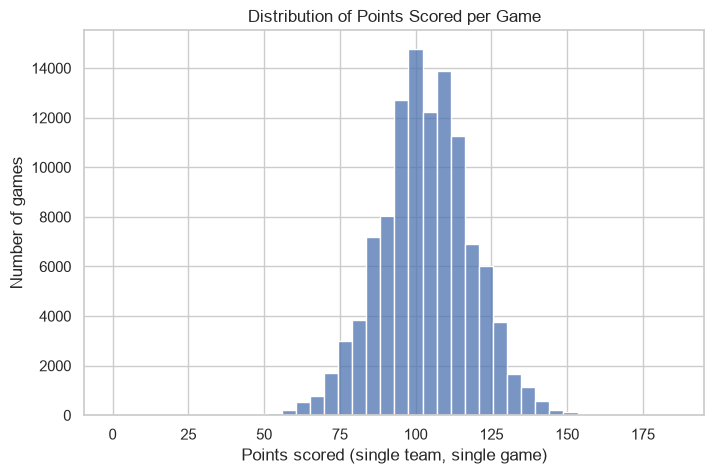

In [17]:
# 1. Histogram of points scored per game (numerical)
plt.figure(figsize=(8, 5))
sns.histplot(df["pts"], bins=40, color="#4C72B0")
plt.title("Distribution of Points Scored per Game")
plt.xlabel("Points scored (single team, single game)")
plt.ylabel("Number of games")
plt.show()

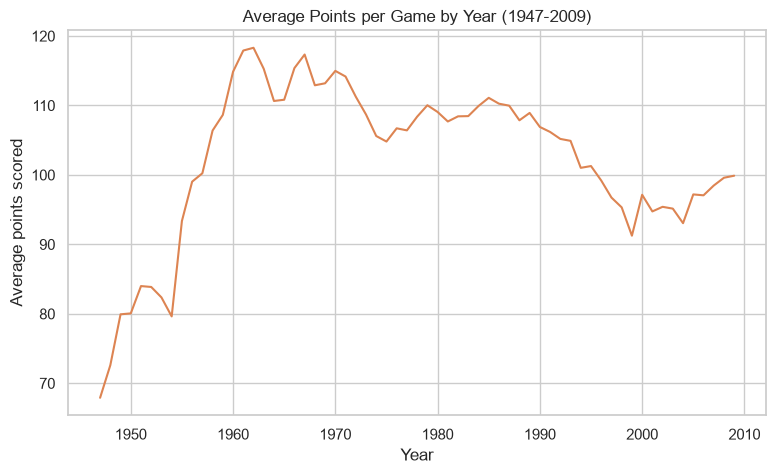

In [18]:
# 2. Average points per game by year (numerical, trend over time)
by_year = df.groupby("year_id")["pts"].mean()

plt.figure(figsize=(9, 5))
plt.plot(by_year.index, by_year.values, color="#DD8452")
plt.title("Average Points per Game by Year (1947-2009)")
plt.xlabel("Year")
plt.ylabel("Average points scored")
plt.show()

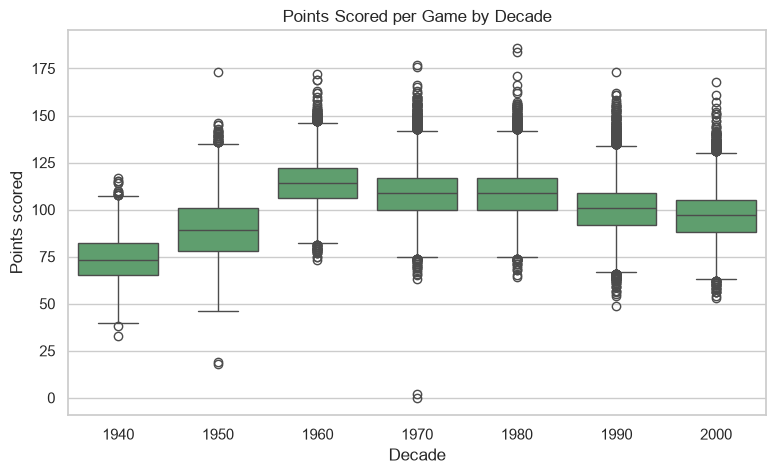

In [19]:
# 3. Points scored by decade (numerical + categorical grouping)
df["decade"] = (df["year_id"] // 10) * 10

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="decade", y="pts", color="#55A868")
plt.title("Points Scored per Game by Decade")
plt.xlabel("Decade")
plt.ylabel("Points scored")
plt.show()

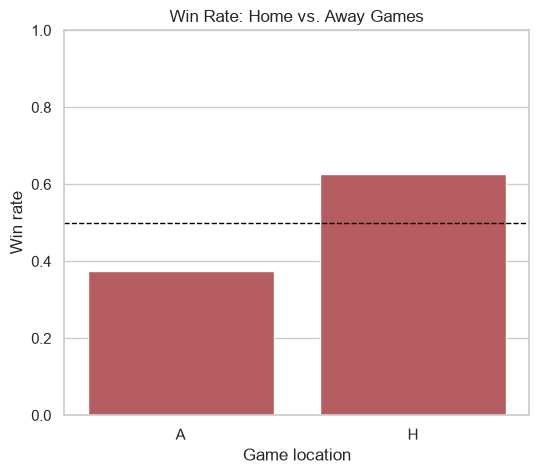

game_location
A    0.373733
H    0.626267
Name: game_result, dtype: float64

In [20]:
# 4. Win rate by game location (categorical)
loc = df[df["game_location"].isin(["H", "A"])]
win_rate_by_loc = loc.groupby("game_location")["game_result"].apply(lambda s: (s == "W").mean())

plt.figure(figsize=(6, 5))
sns.barplot(x=win_rate_by_loc.index, y=win_rate_by_loc.values, color="#C44E52")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1)
plt.title("Win Rate: Home vs. Away Games")
plt.xlabel("Game location")
plt.ylabel("Win rate")
plt.ylim(0, 1)
plt.show()

win_rate_by_loc

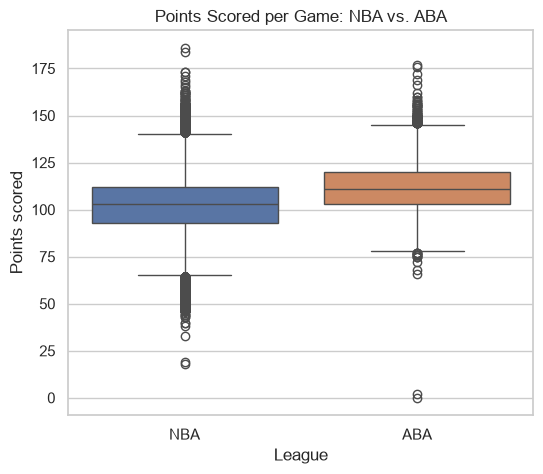

In [21]:
# 5. Points scored by league: NBA vs ABA (categorical, group comparison)
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="lg_id", y="pts", palette=["#4C72B0", "#DD8452"], hue="lg_id", legend=False)
plt.title("Points Scored per Game: NBA vs. ABA")
plt.xlabel("League")
plt.ylabel("Points scored")
plt.show()

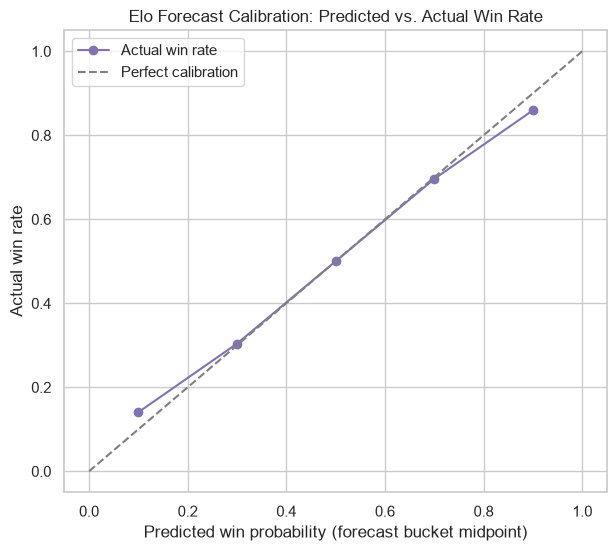

forecast_bucket
(0.0, 0.2]    0.140588
(0.2, 0.4]    0.303908
(0.4, 0.6]    0.500000
(0.6, 0.8]    0.696081
(0.8, 1.0]    0.859412
Name: game_result, dtype: float64

In [22]:
# 6. Relationship: pre-game Elo forecast vs. actual win rate (calibration)
df["forecast_bucket"] = pd.cut(df["forecast"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
calibration = df.groupby("forecast_bucket", observed=True)["game_result"].apply(lambda s: (s == "W").mean())
bucket_midpoints = [0.1, 0.3, 0.5, 0.7, 0.9]

plt.figure(figsize=(7, 6))
plt.plot(bucket_midpoints, calibration.values, marker="o", color="#8172B2", label="Actual win rate")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
plt.title("Elo Forecast Calibration: Predicted vs. Actual Win Rate")
plt.xlabel("Predicted win probability (forecast bucket midpoint)")
plt.ylabel("Actual win rate")
plt.legend()
plt.show()

calibration

## Section 7: What Did You Discover?

**1. Histogram of points per game.** The distribution is roughly bell-shaped and centered around 100–105 points, with a mild right tail extending toward 150–186 points. This matches my general expectation that scoring is fairly regular, but the tail is a reminder that a handful of very high-scoring (often overtime) games exist. This raises the question of whether those tail games are disproportionately overtime games — worth checking against a "minutes played" or "OT" indicator if one existed.

**2. Average points per year (1947–2009).** This was the most informative plot for question 1. Scoring rose steeply from the late 1940s (under 70 points per game) to a clear peak in the 1960s, then **declined** through the 1980s–2000s to under 100 points per game by 2009. I expected a steady increase — this was **not** what happened. The decline suggests that eras of NBA history (e.g. rule changes, more physical/defensive styles in the 1990s–2000s) matter more than a simple "the game keeps getting faster" narrative.

**3. Points by decade (boxplot).** This confirms the year-by-year trend in a more compact form: the 1960s decade has the highest median and widest spread, while the 1990s and 2000s show lower medians and comparable spread. It also shows that within every decade there is meaningful game-to-game variability, not just a shift in the average.

**4. Win rate by game location.** Home teams won about **62.6%** of games versus **37.4%** for away teams — a clear and, in my view, larger home advantage than I expected (I guessed 55–58%). This confirms the general direction of my expectation but understates its size. It raises the question of whether the size of the home advantage itself has changed over the decades (e.g., shrunk in recent years, as some sports analysts claim).

**5. Points by league (NBA vs. ABA).** The ABA (1968–1976) averaged noticeably higher scoring (~111.8 points) than the NBA (~102.5 points) across the full 1947–2009 span, with lower variance too. I had not thought about this in my original expectations. This is very likely connected to real rule differences — the ABA introduced the three-point shot years before the NBA adopted it — which raises a new question about whether pace/possessions, not just rule differences, drove the gap.

**6. Elo forecast calibration.** The calibration curve tracks the "perfect calibration" diagonal quite closely: games where the model gave a team a 0–20% chance to win saw that team win about 14% of the time, and games with an 80–100% forecast saw that team win about 86% of the time. This matches my expectation that the Elo-based forecast would be well calibrated. The main surprise is *how* close it tracks — there is no obvious systematic over- or under-confidence at any probability level in this simple 5-bucket view.

## Section 8: Expected vs. Unexpected Findings

| Finding | Expected? | Evidence |
|---|---|---|
| Home teams win substantially more often (62.6% vs. 37.4%) | Yes (direction), but the size was larger than I guessed | Bar chart of win rate by location |
| Scoring rose sharply through the 1960s, then **declined** for the next four decades instead of continuing to rise | No | Line chart of average points by year; boxplot by decade |
| The ABA (1968–1976) scored noticeably more points per game than the NBA did overall | No | Grouped boxplot by league |
| The Elo-based pre-game forecast is closely calibrated to actual outcomes | Yes | Calibration plot / grouped win rates by forecast bucket |

## Section 9: New Questions

1. We observed that league-wide scoring peaked in the 1960s and then declined for decades. This raises the question of **which specific rule or strategy changes** (e.g. the widening of defensive rules, the "hand-checking" era of the 1990s, changes in pace/possessions per game) are responsible, since "the game gets faster over time" does not explain a decades-long decline.
2. We observed that the ABA scored more per game than the NBA. This raises the question of whether that gap is driven mainly by **pace** (more possessions per game) or by **shot selection** (the ABA's early adoption of the three-point line) — this would require possession-level or shot-attempt data that isn't in this dataset.
3. We observed a clear home-court advantage in win rate. This raises the question of whether that advantage has **shrunk or grown over time**, and whether it differs between the regular season and the playoffs, where crowd and travel effects might interact differently with heightened stakes.
4. We found one game that was a forfeit rather than a genuinely played 0-point game. This raises the question of **how many other non-standard games** (lockout-shortened seasons, exhibition or all-star-type entries, suspended games) might exist in the dataset and should be identified before any deeper statistical modelling is attempted.

## Section 10: Conclusion

This dataset turned out to be much richer than a simple win/loss log. Working through it taught me that a table of "boring" box scores can still hold real surprises once you look past the obvious summary numbers. The most important pattern I found was the long-run trajectory of scoring: rather than a steady modern-era increase, average points per game rose sharply into the 1960s and then declined for roughly four decades afterward. This directly contradicted my initial expectation and was, by a clear margin, the most surprising finding of the whole analysis — it reframed how I think about "pace of play" as something that has moved in multiple directions across NBA history rather than in one steady trend.

Two of my five expectations were reasonably well supported: the home-court advantage clearly exists (though it was stronger than I guessed, at roughly 63% rather than 55–58%), and the Elo-based forecast is well calibrated, which matches the fact that Elo systems are explicitly built and tuned to predict outcomes. My playoff-scoring expectation was only weakly supported — playoff games do score slightly lower on average than regular-season games, but the difference (about two points) was smaller than I anticipated, suggesting that "playoff defense" is a real but modest effect rather than a dramatic one.

The data-quality check was also worthwhile on its own: finding a single forfeited game hiding among 110,902 rows shows why it matters to actually read flagged/unusual rows (via the `notes` column) rather than only look at aggregate statistics, since a single mislabeled 0-point "loss" could distort a scoring analysis if left unexamined.

If I continued this analysis, I would want to bring in possession-level data (to separate pace from shot selection when comparing the ABA and NBA), a cleaner date field, and per-decade home-advantage figures to test whether that advantage has itself been changing over time.